In [1]:
from google.colab import drive
drive.mount('/content/drive')

output_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/"

Mounted at /content/drive


Import Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

Import Files

In [4]:
from google.colab import files
uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv


In [5]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training data shape: ", train_df.shape)
print("Testingg data shape: ", test_df.shape)

Training data shape:  (1460, 81)
Testingg data shape:  (1459, 80)


In [6]:
train_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
train_df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


# Check target variable

In [9]:
#check target variable

train_df["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


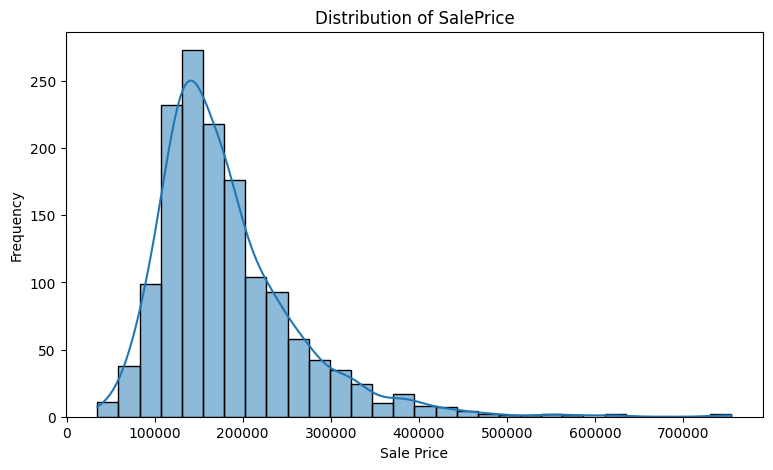

In [10]:
#visualize the target variable

plt.figure(figsize=(9, 5))

sns.histplot(
    train_df["SalePrice"],
    bins=30,
    kde=True
)

plt.title("Distribution of SalePrice")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

In [11]:
#check skewness of SalePrice

print("SalePrice skewness: ", train_df["SalePrice"].skew())

SalePrice skewness:  1.8828757597682129


SalePrice is positively skewed, with a small number of highly priced properties. Therefore,  a log transformation was considered to reduce skewness and stabilize the target distribution before modeling.

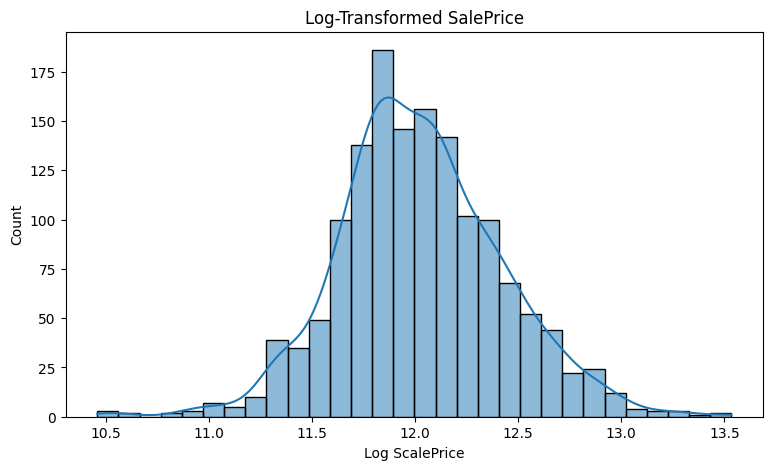

In [12]:
#log transformation - because house prices are usually right-skewed.

plt.figure(figsize=(9, 5))

sns.histplot(
    np.log1p(train_df["SalePrice"]),
    bins=30,
    kde=True
)

plt.title("Log-Transformed SalePrice")
plt.xlabel("Log ScalePrice")

plt.show()

# Data Cleaning

In [13]:
#Duplicate checking

duplicates = train_df.duplicated().sum()
print("Number of duplicate rows: ", duplicates)

Number of duplicate rows:  0


No duplicates records were identified.

In [14]:
#check missing values

missing_count = train_df.isnull().sum()

missing_percent = (
    train_df.isnull().sum() / len(train_df)
) * 100

missing_df = pd.DataFrame({
    "Missing_Count" : missing_count,
    "Missing_Percentage" : missing_percent
})

missing_df = missing_df[
    missing_df["Missing_Count"] > 0
]

missing_df = missing_df.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_df

,Missing_Count,Missing_Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


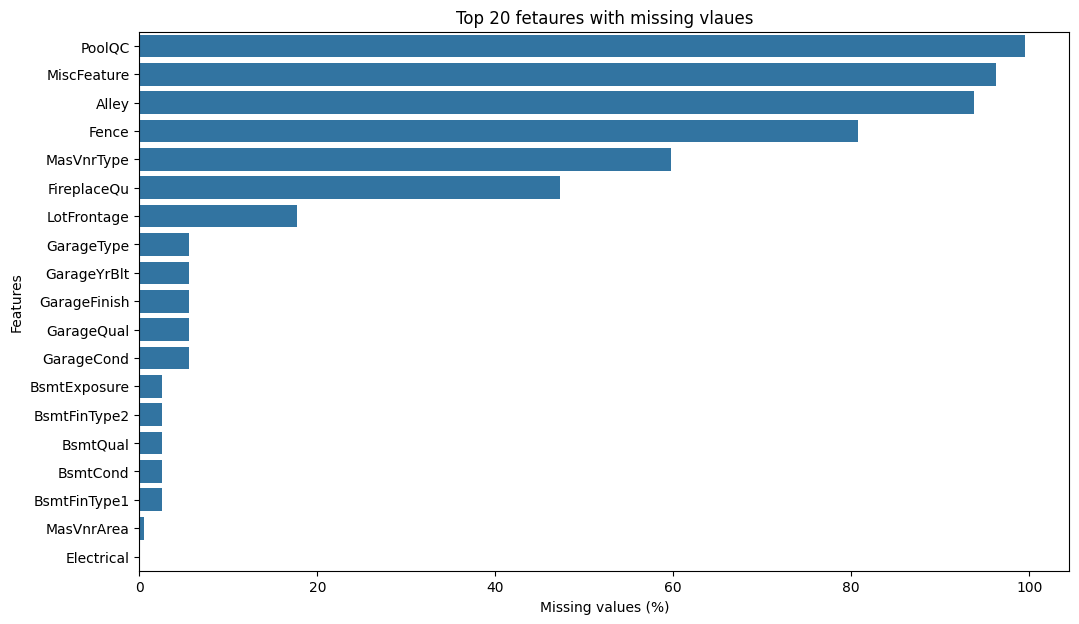

In [15]:
#missing value visualization

plt.figure(figsize=(12, 7))

top_missing = missing_df.head(20)

sns.barplot(
    x=top_missing["Missing_Percentage"],
    y=top_missing.index
)

plt.title("Top 20 fetaures with missing vlaues")
plt.xlabel("Missing values (%)")
plt.ylabel("Features")

plt.show()

In [16]:
#separate target and predictions

y = train_df["SalePrice"]
X = train_df.drop(columns=["SalePrice"])

In [18]:
#ID handling

test_id = test_df["Id"].copy()

X = X.drop(columns=["Id"])
test_X = test_df.drop(columns=["Id"])

In [19]:
#Correct Feature Types

#1. convert code-like variables into categorical variables

#MSSubClass
X["MSSubClass"] = X["MSSubClass"].astype(str)
test_X["MSSubClass"] = test_X["MSSubClass"].astype(str)

#MoSold
X["MoSold"] = X["MoSold"].astype(str)
test_X["MoSold"] = test_X["MoSold"].astype(str)

In [20]:
#2. replace meaningful missing categorical values with "None".

none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "MasVnrType"
]

for col in none_cols:

  if col in X.columns:
    X[col] = X[col].fillna("None")

  if col in test_X.columns:
    test_X[col] = test_X[col].fillna("None")

In [21]:
#replace meaningful numerical missing values with 0

zero_cols = [
    "GarageCars",
    "GarageArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "MasVnrArea"
]

for col in zero_cols:
  if col in X.columns:
    X[col] = X[col].fillna(0)

  if col in test_X.columns:
    test_X[col] = test_X[col].fillna(0)

In [22]:
#check remaining missing values

remaining_missing = X.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print(remaining_missing)

LotFrontage    259
GarageYrBlt     81
Electrical       1
dtype: int64


In [23]:
X.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,Inside,...,0,0,None,None,None,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,...,0,0,None,None,None,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,Inside,...,0,0,None,None,None,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,Corner,...,0,0,None,None,None,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,FR2,...,0,0,None,None,None,0,12,2008,WD,Normal


# **EDA - Correlation with SalePrice**

In [24]:
numeric_data = train_df.select_dtypes(include=np.number)

correlation = (
    numeric_data.corr()["SalePrice"]
    .sort_values(ascending=False)
)

print(correlation.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


Correlation Heatmap

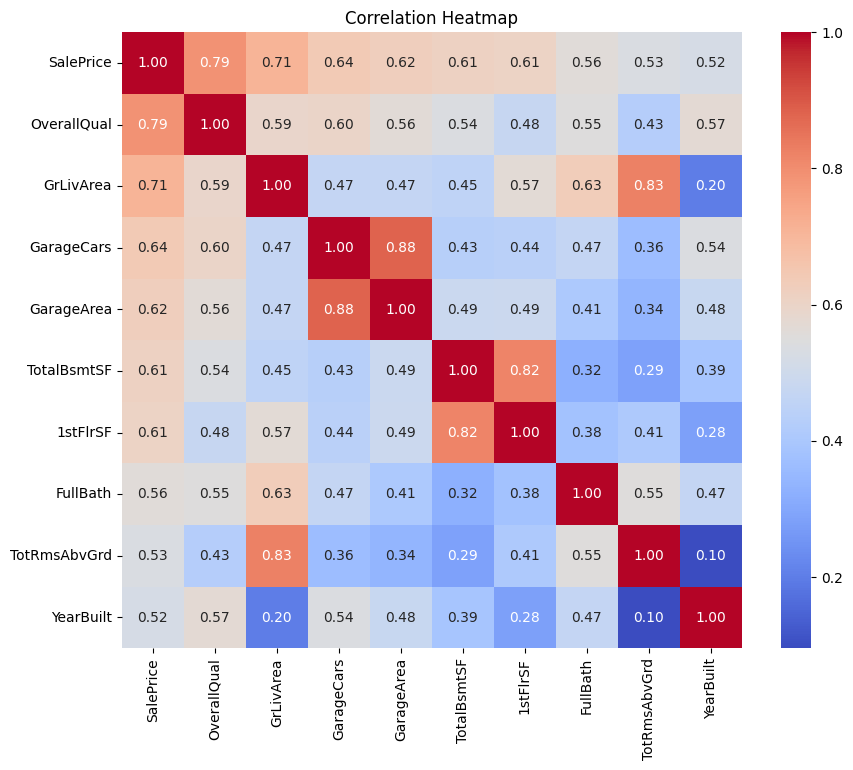

In [25]:
top_features = [
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    train_df[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

**Overall quality vs SalePrice**

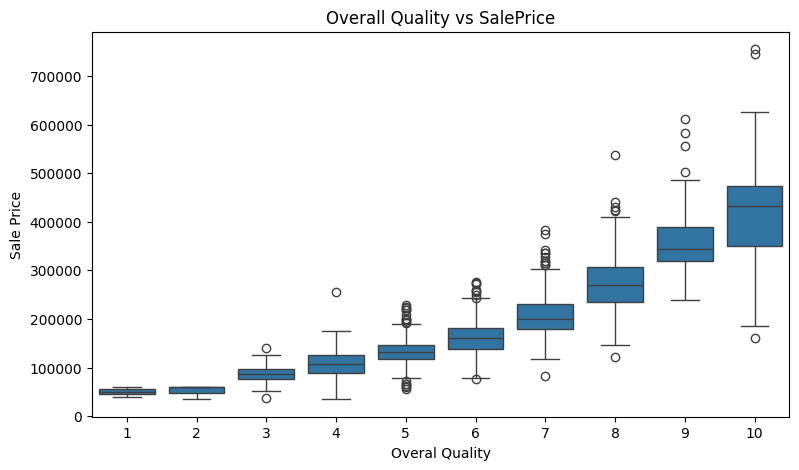

In [26]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs SalePrice")
plt.xlabel("Overal Quality")
plt.ylabel("Sale Price")

plt.show()

Median sale prices increase substantially as OverallQual increases, indicating that overall construction and finish quality is a major determinant of property value.

**Living Area vs SalePrice**

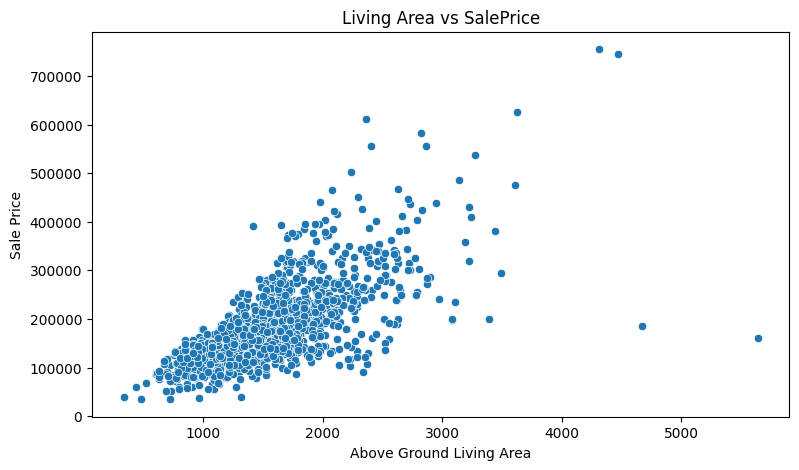

In [27]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=train_df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs SalePrice")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")

plt.show()


Sale price generally increases with above-ground living area, although several extreme observations are visible.

**Neighborhood vs SalePrice**

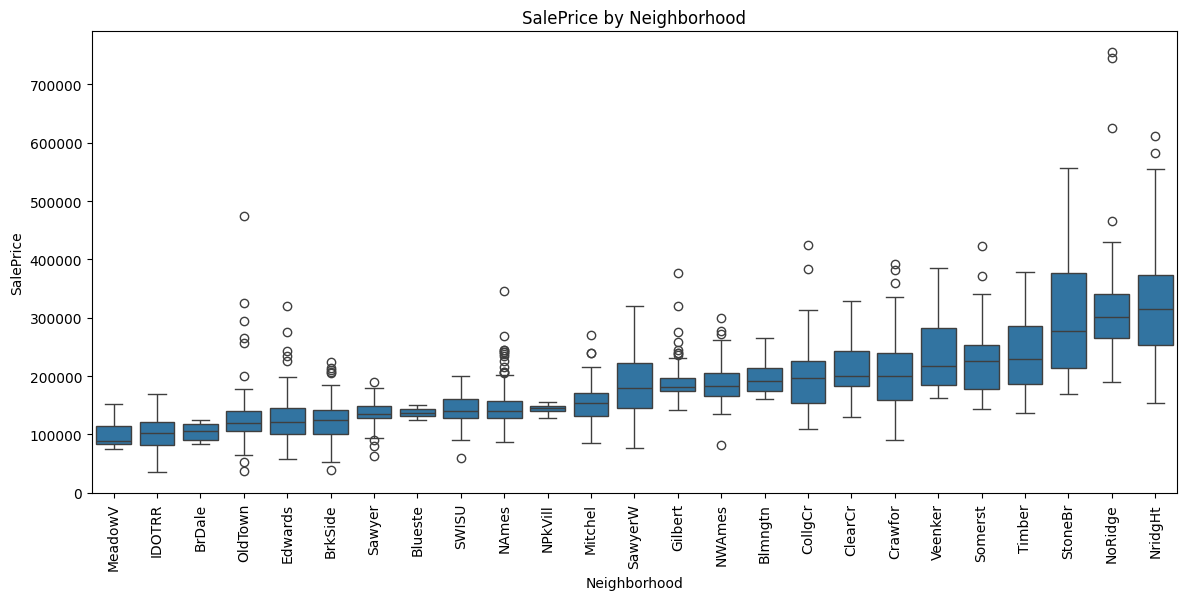

In [28]:
plt.figure(figsize=(14, 6))

order = (
    train_df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=train_df,
    x="Neighborhood",
    y="SalePrice",
    order=order
)

plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood")
plt.show()

Sale-price distributions vary substantially across neighborhoods, suggesting that location should be retained as an important categorical predictor.

# Outliers

In [29]:
numeric_cols = X.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numeric_cols:

    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (X[col] < lower) |
        (X[col] > upper)
    ).sum()

    outlier_summary.append([col, count])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Feature", "Outlier_Count"]
)

outlier_df = outlier_df.sort_values(
    by="Outlier_Count",
    ascending=False
)

outlier_df.head(20)

,Feature,Outlier_Count
28,EnclosedPorch,208
8,BsmtFinSF2,167
3,OverallCond,125
30,ScreenPorch,116
6,MasVnrArea,98
0,LotFrontage,88
16,BsmtHalfBath,82
27,OpenPorchSF,77
1,LotArea,69
20,KitchenAbvGr,68


Inspect possible outliers

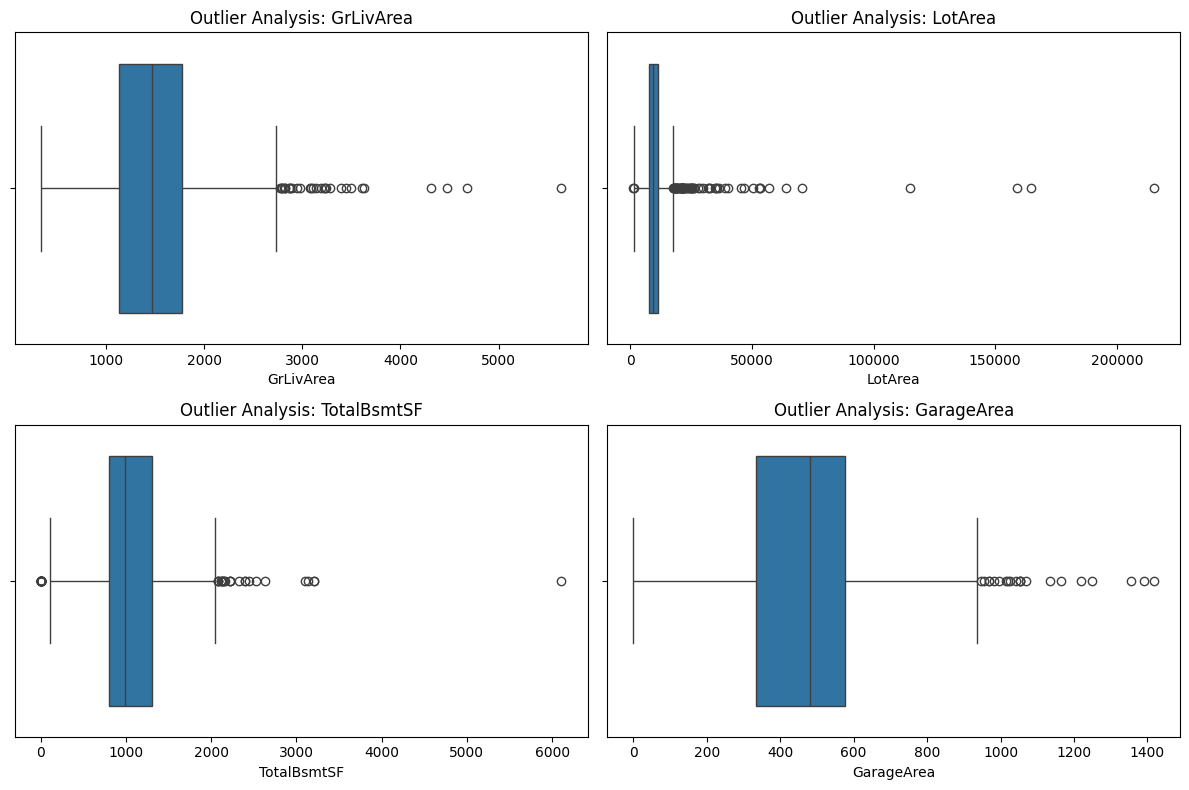

In [30]:
outlier_features = [
    "GrLivArea",
    "LotArea",
    "TotalBsmtSF",
    "GarageArea"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), outlier_features):
    sns.boxplot(x=train_df[col], ax=ax)
    ax.set_title(f"Outlier Analysis: {col}")

plt.tight_layout()
plt.show()

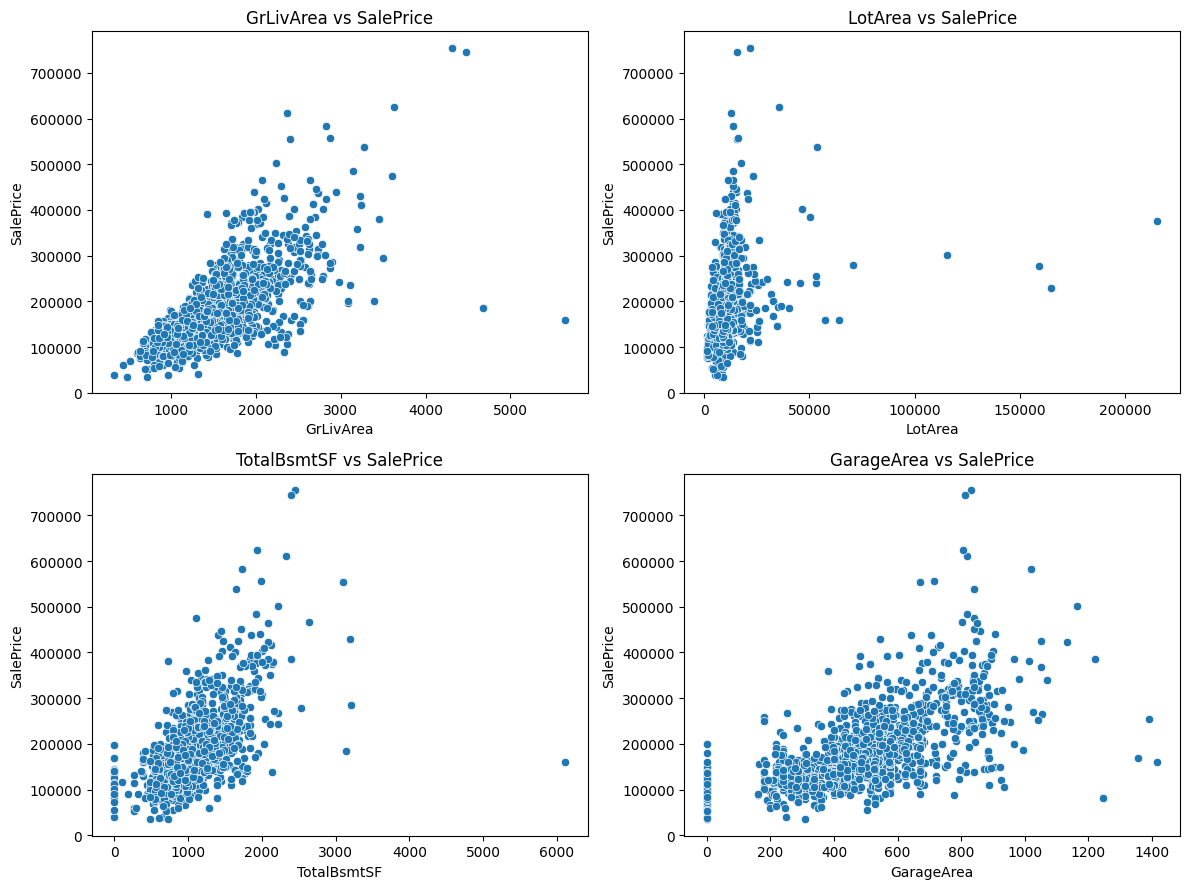

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flatten(), outlier_features):
    sns.scatterplot(
        data=train_df,
        x=col,
        y="SalePrice",
        ax=ax
    )

    ax.set_title(f"{col} vs SalePrice")

plt.tight_layout()
plt.show()

IQR analysis identified multiple statistically extreme observations. However, many represent legitimate differences in property size and amenities rather than data errors. Therefore, no observations were removed automatically. Selected high-value continuous variables were investigated visually before modelling.

# Feature Emgineering

In [32]:
# a reusable function for feature engineering

def create_features(df):
  df = df.copy()

  #Total floor area
  df["TotalSF"] = (
      df["TotalBsmtSF"] +
      df["1stFlrSF"] +
      df["2ndFlrSF"]
  )


  #Total Bathrooms
  df["TotalBathrooms"] = (
      df["FullBath"] +
      0.5 * df["HalfBath"] +
      df["BsmtFullBath"] +
      0.5 * df["BsmtHalfBath"]
  )


  #Age when sold
  df["HouseAge"] = (
      df["YrSold"] - df["YearBuilt"]
  )


  #Time since most recent remodel
  df["YearsSinceRemodel"] = (
      df["YrSold"] - df["YearRemodAdd"]
  )


  #Total outdoor area
  df["TotalPorchSF"] = (
      df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"]
  )

  #Facility Indicator

  #HasGarage
  df["HasGarage"] = (
      df["GarageArea"] > 0
  ).astype(int)

  #HasBasement
  df["HasBasement"] = (
      df["TotalBsmtSF"] > 0
  ).astype(int)

  #HasFireplace
  df["HasFireplace"] = (
      df["Fireplaces"] > 0
  ).astype(int)

  #HasPool
  df["HasPool"] = (
      df["PoolArea"] > 0
  ).astype(int)

  return df

# These calls should be outside the function definition and unindented
X = create_features(X)
test_X = create_features(test_X)


Check engineered features

In [33]:
X[
    [
        "TotalSF",
        "TotalBathrooms",
        "HouseAge",
        "YearsSinceRemodel",
        "TotalPorchSF",
        "HasGarage",
        "HasBasement",
        "HasFireplace",
        "HasPool"
    ]
].head()

,TotalSF,TotalBathrooms,HouseAge,YearsSinceRemodel,TotalPorchSF,HasGarage,HasBasement,HasFireplace,HasPool
0,2566,3.5,5,5,61,1,1,0,0
1,2524,2.5,31,31,298,1,1,1,0
2,2706,3.5,7,6,42,1,1,1,0
3,2473,2.0,91,36,307,1,1,1,0
4,3343,3.5,8,8,276,1,1,1,0


In [34]:
y_log = np.log1p(y)

print("Original skewness:", y.skew())
print("Log-transformed skewness:", y_log.skew())

Original skewness: 1.8828757597682129
Log-transformed skewness: 0.12134661989685333


Identify numerical and categorical features

In [35]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 43
Categorical features: 45


# Preprocessing Pipeline

Numerical Preprocessing

In [36]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

For every numerical feature, first handle missing values, then scale the values.

Categorical Preprocessing

In [37]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

Combine preprocessing

In [38]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Feature Selection

using,
1. Filter method: correlation for numerical features.
2. Embedded/model-based method: Lasso and/or Random Forest.

# Correlation analysis after feature engineering

In [39]:
feature_data = X.copy()
feature_data["SalePrice"] = y

numeric_corr = (
    feature_data
    .select_dtypes(include=np.number)
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(numeric_corr.head(20))

OverallQual          0.790982
TotalSF              0.782260
GrLivArea            0.708624
GarageCars           0.640409
TotalBathrooms       0.631731
GarageArea           0.623431
TotalBsmtSF          0.613581
1stFlrSF             0.605852
FullBath             0.560664
TotRmsAbvGrd         0.533723
HouseAge            -0.523350
YearBuilt            0.522897
YearsSinceRemodel   -0.509079
YearRemodAdd         0.507101
GarageYrBlt          0.486362
MasVnrArea           0.472614
HasFireplace         0.471908
Fireplaces           0.466929
TotalPorchSF         0.390993
BsmtFinSF1           0.386420
Name: SalePrice, dtype: float64


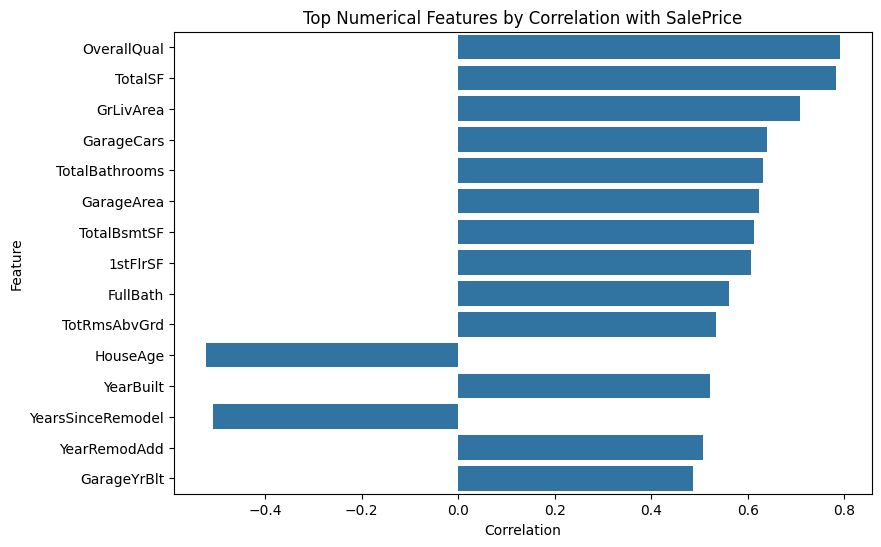

In [40]:
top_corr = numeric_corr.head(15)

plt.figure(figsize=(9,6))

sns.barplot(
    x = top_corr.values,
    y = top_corr.index
)

plt.title("Top Numerical Features by Correlation with SalePrice")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()

In [41]:
selected_numeric = numeric_corr[
    numeric_corr.abs() >= 0.10
].index.tolist()

print("Selected numerical features:")
print(selected_numeric)

print("\nNumber selected:", len(selected_numeric))

Selected numerical features:
['OverallQual', 'TotalSF', 'GrLivArea', 'GarageCars', 'TotalBathrooms', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'HouseAge', 'YearBuilt', 'YearsSinceRemodel', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'HasFireplace', 'Fireplaces', 'TotalPorchSF', 'BsmtFinSF1', 'LotFrontage', 'WoodDeckSF', '2ndFlrSF', 'OpenPorchSF', 'HalfBath', 'LotArea', 'HasGarage', 'BsmtFullBath', 'BsmtUnfSF', 'BedroomAbvGr', 'HasBasement', 'KitchenAbvGr', 'EnclosedPorch', 'ScreenPorch']

Number selected: 34


# ANOVA for feature selection

In [42]:
print("Number of categorical features:", len(categorical_features))
print(categorical_features)

Number of categorical features: 45
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'MoSold', 'SaleType', 'SaleCondition']


In [43]:
from scipy.stats import f_oneway

anova_results = []

for col in categorical_features:

    # Create one SalePrice group for each category
    groups = [
        y[X[col] == category]
        for category in X[col].dropna().unique()
    ]

    # Remove groups with fewer than 2 observations
    groups = [group for group in groups if len(group) >= 2]

    # Run ANOVA
    if len(groups) >= 2:
        f_stat, p_value = f_oneway(*groups)

        anova_results.append({
            "Feature": col,
            "F_statistic": f_stat,
            "P_value": p_value
        })

# Convert results to DataFrame
anova_df = pd.DataFrame(anova_results)

# Sort from smallest p-value
anova_df = anova_df.sort_values(
    "P_value",
    ascending=True
).reset_index(drop=True)

# Display all results
anova_df

,Feature,F_statistic,P_value
0,Neighborhood,71.784865,1.558600e-225
1,ExterQual,443.334831,1.439551e-204
2,BsmtQual,316.148635,8.158548e-196
3,KitchenQual,407.806352,3.032213e-192
4,GarageFinish,213.867028,6.228747e-115
5,FireplaceQu,121.075121,2.971217e-107
6,Foundation,100.253851,5.791895e-91
7,GarageType,80.379992,6.117026e-87
8,MSSubClass,33.732076,8.662166e-79
9,BsmtFinType1,64.688200,2.386358e-71


In [44]:
anova_df["Significant"] = anova_df["P_value"] < 0.05

anova_df

,Feature,F_statistic,P_value,Significant
0,Neighborhood,71.784865,1.558600e-225,True
1,ExterQual,443.334831,1.439551e-204,True
2,BsmtQual,316.148635,8.158548e-196,True
3,KitchenQual,407.806352,3.032213e-192,True
4,GarageFinish,213.867028,6.228747e-115,True
5,FireplaceQu,121.075121,2.971217e-107,True
6,Foundation,100.253851,5.791895e-91,True
7,GarageType,80.379992,6.117026e-87,True
8,MSSubClass,33.732076,8.662166e-79,True
9,BsmtFinType1,64.688200,2.386358e-71,True


P_value < 0.05 → evidence that SalePrice differs among categories → potentially useful feature.

P_value >= 0.05 → ANOVA did not find sufficient evidence of different mean SalePrice among its categories.

In [45]:
print(
    "Significant categorical features:",
    anova_df["Significant"].sum()
)

print(
    "Non-significant categorical features:",
    (~anova_df["Significant"]).sum()
)

Significant categorical features: 41
Non-significant categorical features: 3


In [46]:
selected_categorical = anova_df[
    anova_df["P_value"] < 0.05
]["Feature"].tolist()

print(selected_categorical)
print("Total:", len(selected_categorical))

['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'MSSubClass', 'BsmtFinType1', 'HeatingQC', 'MasVnrType', 'BsmtExposure', 'Exterior1st', 'SaleCondition', 'Exterior2nd', 'SaleType', 'MSZoning', 'HouseStyle', 'GarageQual', 'GarageCond', 'LotShape', 'CentralAir', 'Electrical', 'PavedDrive', 'RoofStyle', 'BsmtCond', 'Fence', 'BldgType', 'RoofMatl', 'LandContour', 'BsmtFinType2', 'Condition1', 'Alley', 'ExterCond', 'PoolQC', 'LotConfig', 'Functional', 'Heating', 'MiscFeature', 'Condition2']
Total: 41


remove all failed categorical features

In [47]:
failed_categorical = anova_df.loc[
    anova_df["Significant"] == False,
    "Feature"
]. tolist()

print("Features to remove: ")
print(failed_categorical)

X = X.drop(columns=failed_categorical)

test_X = test_X.drop(columns=failed_categorical)

print("New X shape:", X.shape)
print("New test_X shape:", test_X.shape)

Features to remove: 
['Street', 'LandSlope', 'MoSold']
New X shape: (1460, 85)
New test_X shape: (1459, 85)


# Selected Features

In [48]:
# Numerical features passing correlation threshold
selected_numeric = numeric_corr[
    numeric_corr.abs() >= 0.10
].index.tolist()

# Categorical features passing ANOVA
selected_categorical = anova_df.loc[
    anova_df["P_value"] < 0.05,
    "Feature"
].tolist()

# Combine
selected_features = selected_numeric + selected_categorical

print("Selected numerical:", len(selected_numeric))
print("Selected categorical:", len(selected_categorical))
print("Total selected:", len(selected_features))

Selected numerical: 34
Selected categorical: 41
Total selected: 75


In [49]:
X = X[selected_features]
test_X = test_X[selected_features]

recreate the feature list

In [50]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=[object, "category"]
).columns.tolist()

# Final Datasets

In [ ]:
output_path = "/content/drive/MyDrive/ML_Assignment/Results/Outputs/"

# Training dataset
final_train = X.copy()
final_train["SalePrice"] = y

# Test dataset
final_test = test_X.copy()

# Save
final_train.to_csv(
    output_path + "final_preprocessed_train.csv",
    index=False
)

final_test.to_csv(
    output_path + "final_preprocessed_test.csv",
    index=False
)

print("Train saved:", final_train.shape)
print("Test saved:", final_test.shape)
print("Both datasets saved successfully!")